# 対応づけた LC4 を刺激する

`lc4_camera_map.ipynb` が付けた画面上の位置と、`data/malecns/gf-loom/` の化学シナプス数を使い、画面の一部だけを刺激したときに左右の DNp01 へ何が入るかを見る。LPLC2 にはまだ位置が無いので、ここは LC4 だけを刺激する。

見たいのは、126 本を場所で分けて動かしたときに、出力が左右 2 本の電流以外のものを持つかである。車輪のヨーは、発火したあとで右の発火率から左の発火率を引いた符号を使う。正が左旋回である。

定数は `gf_loom_sim.ipynb` と同じである。結合の本数だけがコネクトームから来ていて、発火率と閾値はそこで選べる値のままにしてある。計測にフィットしたモデルではない。


In [1]:
from pathlib import Path

import japanize_matplotlib
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import pyarrow.feather as feather

ROOT = Path.cwd().resolve()
while ROOT != ROOT.parent and not (ROOT / "data" / "malecns" / "gf-loom" / "neurons.feather").exists():
    ROOT = ROOT.parent
DATA = ROOT / "data" / "malecns" / "gf-loom"
CACHE = ROOT / "data" / "malecns" / "lc4-camera" / "lc4_lobula_posts.npz"
neurons = feather.read_table(DATA / "neurons.feather").to_pandas()
edges = feather.read_table(DATA / "edges.feather").to_pandas()
pack = np.load(CACHE)
print(f"neurons {len(neurons)}  edges {len(edges)}  cache {CACHE.relative_to(ROOT)}")


neurons 327  edges 20684  cache data/malecns/lc4-camera/lc4_lobula_posts.npz


## 位置と重み

各細胞の画面位置は、小葉の後シナプスが載る列の平均である。左端が 0、右端が 1、上が 0。範囲は LC4 が触れた列ではなく、小葉の全列である。`lc4_camera_map.ipynb` の「画像上の位置」と同じ対応で、帯ごとに上下を引き伸ばした位置はここでは使わない。

重みは、その細胞から同側の DNp01 への化学シナプス数である。電流の基準は、その側の LC4 と LPLC2 から DNp01 への化学シナプスの合計で、`gf_loom_sim.ipynb` の「側ごと」と同じである。LPLC2 は刺激しないが、基準の中には残す。


LC4 左 71 本、シナプス 3782    右 55 本、シナプス 2580
LPLC2 → DNp01 は刺激しない。基準にだけ入れる。左 2642  右 2220
1 本の重み 左  30–53–86
1 本の重み 右  21–47–67
左半面を横 4 等分したときの重み
  u 0.00–0.12   9 本  重み 0.133
  u 0.12–0.25  26 本  重み 0.391
  u 0.25–0.38  27 本  重み 0.355
  u 0.38–0.50   9 本  重み 0.122
右半面を横 4 等分したときの重み
  u 0.50–0.62   8 本  重み 0.139
  u 0.62–0.75  20 本  重み 0.346
  u 0.75–0.88  20 本  重み 0.376
  u 0.88–1.00   7 本  重み 0.139


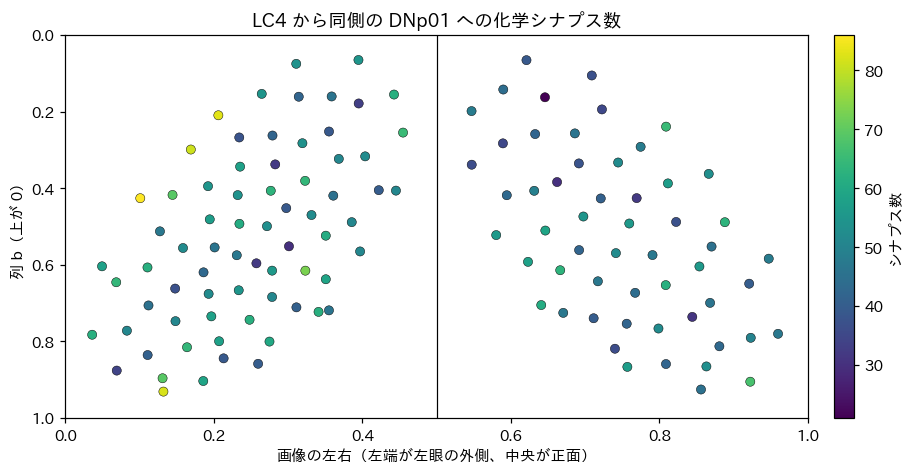

In [2]:
def image_uv(ab, side, left_ab, right_ab):
    """u is 0 at the left edge and 1 at the right edge. v is 0 at the top."""
    u = np.empty(len(ab), dtype=np.float64)
    v = np.empty(len(ab), dtype=np.float64)
    for code, grid in ((0, left_ab), (1, right_ab)):
        valid = grid[:, 0] >= 0
        a0, a1 = grid[valid, 0].min(), grid[valid, 0].max()
        b0, b1 = grid[valid, 1].min(), grid[valid, 1].max()
        mask = side == code
        lateral = (ab[mask, 0] - a0) / (a1 - a0)
        if code == 0:
            u[mask] = 0.5 * (1.0 - lateral)
        else:
            u[mask] = 0.5 + 0.5 * lateral
        v[mask] = (ab[mask, 1] - b0) / (b1 - b0)
    return u, v


syn_body = pack["body"]
syn_side = pack["side"]
syn_u, syn_v = image_uv(pack["ab"], syn_side, pack["left_ab"], pack["right_ab"])
order = np.argsort(syn_body, kind="mergesort")
syn_body = syn_body[order]
syn_u = syn_u[order]
syn_v = syn_v[order]
syn_side = syn_side[order]
cuts = np.flatnonzero(np.diff(syn_body)) + 1
starts = np.r_[0, cuts]
cell_n = np.diff(np.r_[starts, len(syn_body)])
cell_id = syn_body[starts]
cell_side = syn_side[starts]
cell_u = np.add.reduceat(syn_u, starts) / cell_n
cell_v = np.add.reduceat(syn_v, starts) / cell_n
if np.any(np.maximum.reduceat(syn_side, starts) != np.minimum.reduceat(syn_side, starts)):
    raise RuntimeError("片眼に収まらない LC4 がある。")

lc4 = neurons.loc[neurons.type == "LC4", ["bodyId", "side"]].rename(
    columns={"bodyId": "body_pre", "side": "side_pre"}
)
gf = neurons.loc[neurons.type == "DNp01", ["bodyId", "side"]].rename(
    columns={"bodyId": "body_post", "side": "side_post"}
)
lplc = neurons.loc[neurons.type == "LPLC2", ["bodyId", "side"]].rename(
    columns={"bodyId": "body_pre", "side": "side_pre"}
)
onto_gf = edges.merge(lc4, on="body_pre").merge(gf, on="body_post")
lplc_onto = edges.merge(lplc, on="body_pre").merge(gf, on="body_post")
if not (onto_gf.side_pre == onto_gf.side_post).all():
    raise RuntimeError("対側への LC4 → DNp01 がある。")
if not onto_gf.nt_sign.eq(1).all():
    raise RuntimeError("LC4 → DNp01 にアセチルコリン以外がある。")
if set(onto_gf.body_pre.astype(np.int64)) != set(cell_id.astype(np.int64)):
    raise RuntimeError("画面上の LC4 と、DNp01 への辺を持つ LC4 が一致しない。")

weight_of = dict(zip(onto_gf.body_pre.astype(np.int64), onto_gf.weight.astype(np.float64)))
cell_w = np.array([weight_of[int(i)] for i in cell_id])
lc4_sum = np.array([cell_w[cell_side == code].sum() for code in (0, 1)])
lplc_sum = np.array([
    float(lplc_onto.loc[lplc_onto.side_post == name, "weight"].sum())
    for name in ("L", "R")
])
side_ref = lc4_sum + lplc_sum

print(
    f"LC4 左 {int((cell_side == 0).sum())} 本、シナプス {lc4_sum[0]:.0f}"
    f"    右 {int((cell_side == 1).sum())} 本、シナプス {lc4_sum[1]:.0f}"
)
print(f"LPLC2 → DNp01 は刺激しない。基準にだけ入れる。左 {lplc_sum[0]:.0f}  右 {lplc_sum[1]:.0f}")
for code, name in ((0, "左"), (1, "右")):
    part = cell_w[cell_side == code]
    print(f"1 本の重み {name}  {part.min():.0f}–{np.median(part):.0f}–{part.max():.0f}")

for code, name, u0, u1 in ((0, "左", 0.0, 0.5), (1, "右", 0.5, 1.0)):
    chosen = cell_side == code
    bins = np.linspace(u0, u1, 5)
    at = np.clip(np.digitize(cell_u[chosen], bins) - 1, 0, 3)
    print(f"{name}半面を横 4 等分したときの重み")
    for band in range(4):
        sel = at == band
        share = cell_w[chosen][sel].sum() / cell_w[chosen].sum()
        print(f"  u {bins[band]:.2f}–{bins[band + 1]:.2f}  {int(sel.sum()):2d} 本  重み {share:.3f}")

fig, ax = plt.subplots(figsize=(8.2, 4.2), constrained_layout=True)
points = ax.scatter(
    cell_u, cell_v, s=36, c=cell_w, cmap="viridis", linewidths=0.3, edgecolors="k"
)
ax.axvline(0.5, color="k", lw=0.8)
ax.set_xlim(0, 1)
ax.set_ylim(1, 0)
ax.set_xlabel("画像の左右（左端が左眼の外側、中央が正面）")
ax.set_ylabel("列 b（上が 0）")
ax.set_title("LC4 から同側の DNp01 への化学シナプス数")
fig.colorbar(points, ax=ax, fraction=0.046, pad=0.02).set_label("シナプス数")
plt.show()


## 刺激

円の中に入った後シナプスの割合を、その細胞の発火率にする。細胞の平均位置が円の外でも、樹状突起が円にかかった列の分は発火する。円の外の列は 0 である。

$$
r_i = R_{\max} \frac{n_i^{\mathrm{in}}}{n_i}, \qquad
I = \frac{\sum_i w_i \, r_i / R_{\mathrm{ref}}}{W_{\mathrm{side}}}
$$

$W_{\mathrm{side}}$ は、その側の LC4 と LPLC2 から DNp01 への化学シナプスの合計である。片眼の両方の細胞種が $R_{\mathrm{ref}}$ で発火しているとき、電流は 1 になる。膜は `gf_loom_sim.ipynb` と同じ電流入力の LIF で、時定数 5 ms、閾値 1、不応期 5 ms、刻み 1 ms である。平衡は電流そのものなので、電流が 1 未満のあいだはスパイクが出ない。

円の半径は画面幅の 0.10。比較として、左の LC4 を全部 $R_{\max}$ にする場面を置く。電流は 150 ms のあいだ一定にする。


In [3]:
R_MAX = 80.0
R_REF = 50.0
TAU_MS = 5.0
V_THRESHOLD = 1.0
REFRAC_MS = 5.0
DT = 0.001
HOLD_S = 0.15
DISK_R = 0.10
SCALE = R_MAX / R_REF


def fraction_in_disk(center_u, center_v, radius):
    inside = (syn_u - center_u) ** 2 + (syn_v - center_v) ** 2 <= radius ** 2
    hit = np.add.reduceat(inside.astype(np.float64), starts)
    return hit / cell_n


def currents(frac):
    """LC4 の重みに占める割合と、DNp01 の電流。並びは左、右。"""
    share = np.zeros(2)
    current = np.zeros(2)
    for index, code in enumerate((0, 1)):
        chosen = cell_side == code
        weighted = float(np.sum(cell_w[chosen] * frac[chosen]))
        share[index] = weighted / lc4_sum[index]
        current[index] = weighted / side_ref[index] * SCALE
    return share, current


def lif(drive):
    """Current-based LIF. `drive` is one sample per DT, in threshold units."""
    voltage = np.empty(len(drive))
    spiked = np.zeros(len(drive), dtype=bool)
    v = 0.0
    silent_until = 0
    refrac_steps = int(round(REFRAC_MS / (DT * 1000)))
    step = (DT * 1000) / TAU_MS
    for i, value in enumerate(drive):
        if i < silent_until:
            v = 0.0
            voltage[i] = 0.0
            continue
        v += step * (-v + float(value))
        if v >= V_THRESHOLD:
            voltage[i] = V_THRESHOLD
            spiked[i] = True
            v = 0.0
            silent_until = i + refrac_steps
        else:
            voltage[i] = v
    return voltage, spiked


TIME_S = np.arange(int(round(HOLD_S / DT))) * DT


def hold(current):
    return lif(np.full(len(TIME_S), current))


## 場面

半径 0.10 の円を、左の中央、右の中央、画面の中央、左の上、左の下に置く。最後は円ではなく、左の LC4 全部を $R_{\max}$ にする。これが、このノートで左の DNp01 に入れられるいちばん大きい電流である。


       場面  LC4の割合 左  LC4の割合 右  電流 左  電流 右  スパイク 左  スパイク 右
     左の中央     0.132     0.000 0.125 0.000       0       0
     右の中央     0.000     0.130 0.000 0.112       0       0
    画面の中央     0.012     0.015 0.011 0.013       0       0
      左の上     0.079     0.000 0.075 0.000       0       0
      左の下     0.114     0.000 0.108 0.000       0       0
左の LC4 全部     1.000     0.000 0.942 0.000       0       0


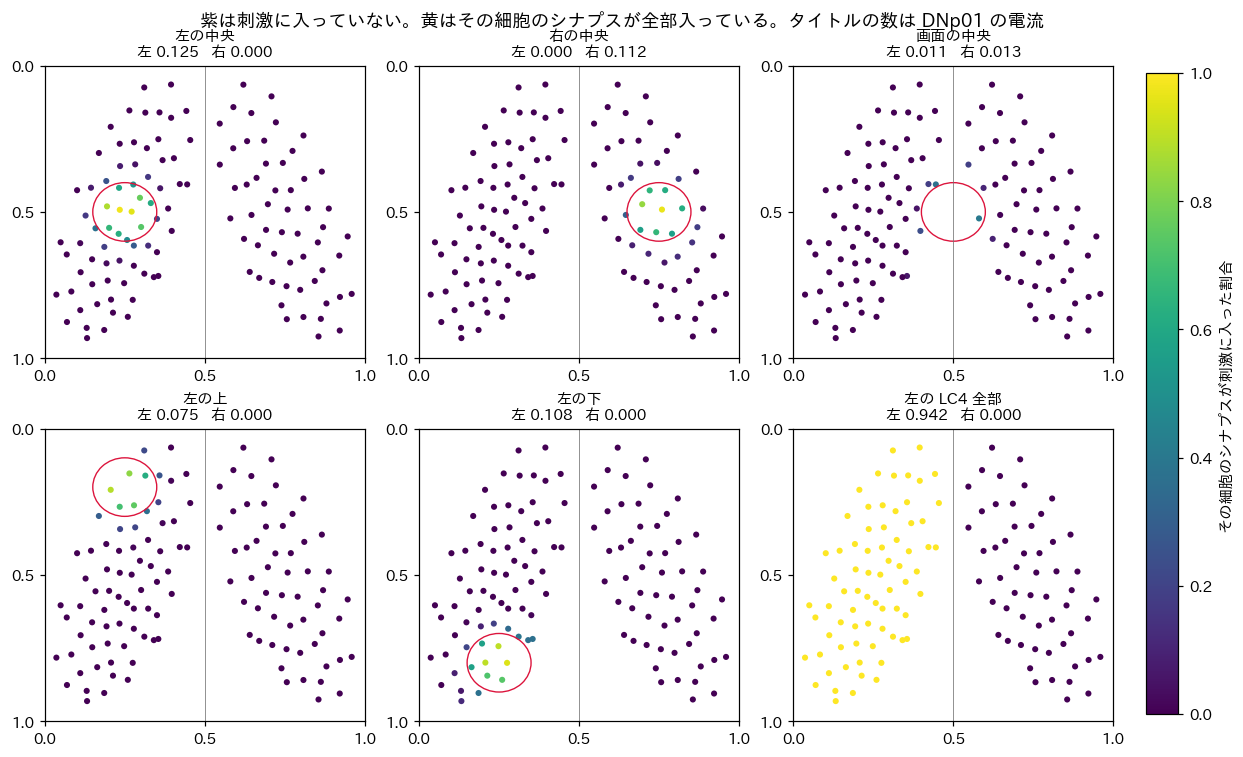

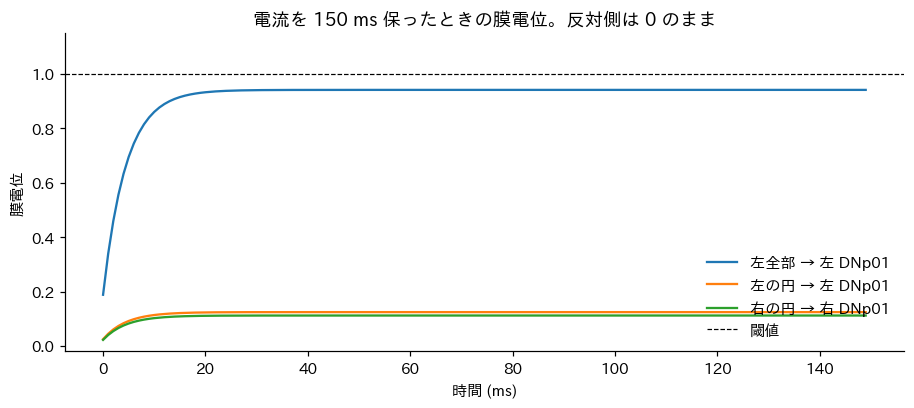

In [4]:
SCENES = [
    {"label": "左の中央", "kind": "disk", "u": 0.25, "v": 0.50},
    {"label": "右の中央", "kind": "disk", "u": 0.75, "v": 0.50},
    {"label": "画面の中央", "kind": "disk", "u": 0.50, "v": 0.50},
    {"label": "左の上", "kind": "disk", "u": 0.25, "v": 0.20},
    {"label": "左の下", "kind": "disk", "u": 0.25, "v": 0.80},
    {"label": "左の LC4 全部", "kind": "half", "side": 0},
]


def scene_fraction(spec):
    if spec["kind"] == "half":
        frac = np.zeros(len(cell_id))
        frac[cell_side == spec["side"]] = 1.0
        return frac
    return fraction_in_disk(spec["u"], spec["v"], DISK_R)


results = {}
rows = []
for spec in SCENES:
    frac = scene_fraction(spec)
    share, current = currents(frac)
    voltage = np.zeros((len(TIME_S), 2))
    spiked = np.zeros((len(TIME_S), 2), dtype=bool)
    for index in (0, 1):
        voltage[:, index], spiked[:, index] = hold(current[index])
    results[spec["label"]] = {
        "frac": frac,
        "share": share,
        "current": current,
        "voltage": voltage,
        "spiked": spiked,
    }
    rows.append({
        "場面": spec["label"],
        "LC4の割合 左": share[0],
        "LC4の割合 右": share[1],
        "電流 左": current[0],
        "電流 右": current[1],
        "スパイク 左": int(spiked[:, 0].sum()),
        "スパイク 右": int(spiked[:, 1].sum()),
    })

left_mid = results["左の中央"]["share"]
if left_mid[1] != 0.0:
    raise RuntimeError("左の円が右の LC4 を刺激している。")
if results["右の中央"]["share"][0] != 0.0:
    raise RuntimeError("右の円が左の LC4 を刺激している。")

table = pd.DataFrame(rows)
print(table.to_string(index=False, float_format=lambda value: f"{value:.3f}"))

fig, axes = plt.subplots(2, 3, figsize=(11.2, 6.6), constrained_layout=True)
color_norm = plt.Normalize(vmin=0.0, vmax=1.0)
for ax, spec in zip(axes.ravel(), SCENES):
    found = results[spec["label"]]
    ax.scatter(
        cell_u,
        cell_v,
        s=16,
        c=found["frac"],
        cmap="viridis",
        norm=color_norm,
        linewidths=0,
    )
    if spec["kind"] == "disk":
        ax.add_patch(
            plt.Circle((spec["u"], spec["v"]), DISK_R, fill=False, color="crimson", lw=0.9)
        )
    ax.axvline(0.5, color="0.45", lw=0.5)
    ax.set_xlim(0, 1)
    ax.set_ylim(1, 0)
    ax.set_xticks([0, 0.5, 1])
    ax.set_yticks([0, 0.5, 1])
    left_i, right_i = found["current"]
    ax.set_title(f"{spec['label']}\n左 {left_i:.3f}   右 {right_i:.3f}", fontsize=10)
fig.colorbar(
    plt.cm.ScalarMappable(norm=color_norm, cmap="viridis"),
    ax=axes,
    fraction=0.03,
    pad=0.02,
).set_label("その細胞のシナプスが刺激に入った割合")
fig.suptitle("紫は刺激に入っていない。黄はその細胞のシナプスが全部入っている。タイトルの数は DNp01 の電流", y=1.02)
plt.show()

fig, ax = plt.subplots(figsize=(8.2, 3.6), constrained_layout=True)
for label, index, name in (
    ("左の LC4 全部", 0, "左全部 → 左 DNp01"),
    ("左の中央", 0, "左の円 → 左 DNp01"),
    ("右の中央", 1, "右の円 → 右 DNp01"),
):
    ax.plot(TIME_S * 1000, results[label]["voltage"][:, index], label=name)
ax.axhline(1.0, color="k", lw=0.8, ls="--", label="閾値")
ax.set_xlabel("時間 (ms)")
ax.set_ylabel("膜電位")
ax.set_ylim(-0.02, 1.15)
ax.legend(frameon=False, loc="lower right")
ax.spines["top"].set_visible(False)
ax.spines["right"].set_visible(False)
ax.set_title("電流を 150 ms 保ったときの膜電位。反対側は 0 のまま")
plt.show()


## 画面を横切る円

同じ半径の円の中心を動かす。上下 0.5 の横一列と、画面全体に中心を置いたときの電流の差である。差は右の電流から左の電流を引いたもので、車のヨーと同じ符号である。正なら左旋回、負なら右旋回になる。黒点は LC4 の平均位置で、円の中心ではない。


横一列の最大  左 0.131  右 0.119
左の u=0.25 で上下を動かす
  v=0.10  LC4の割合 0.041  電流 0.039
  v=0.20  LC4の割合 0.079  電流 0.075
  v=0.30  LC4の割合 0.104  電流 0.098
  v=0.40  LC4の割合 0.128  電流 0.121
  v=0.50  LC4の割合 0.132  電流 0.125
  v=0.60  LC4の割合 0.138  電流 0.130
  v=0.70  LC4の割合 0.140  電流 0.132
  v=0.80  LC4の割合 0.114  電流 0.108
  v=0.90  LC4の割合 0.057  電流 0.054
差の範囲 -0.136 ～ 0.123    和の最大 0.136
左上の角の差 +0.000    右上の角の差 +0.000


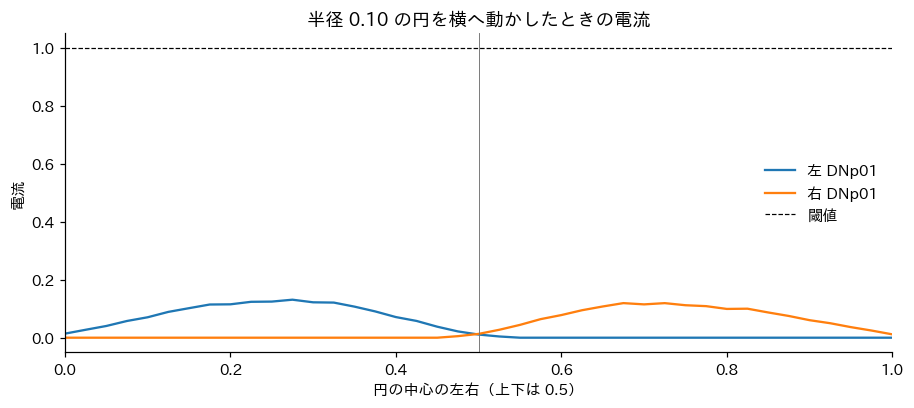

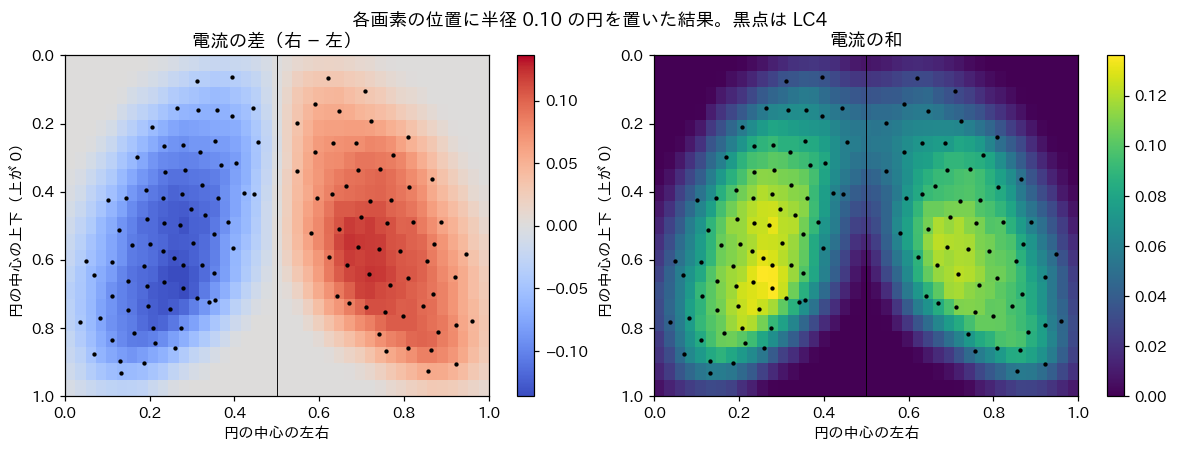

In [5]:
centers_u = np.linspace(0.0, 1.0, 41)
sweep = np.zeros((len(centers_u), 2))
for index, center_u in enumerate(centers_u):
    _, sweep[index] = currents(fraction_in_disk(center_u, 0.5, DISK_R))

fig, ax = plt.subplots(figsize=(8.2, 3.6), constrained_layout=True)
ax.plot(centers_u, sweep[:, 0], label="左 DNp01")
ax.plot(centers_u, sweep[:, 1], label="右 DNp01")
ax.axhline(1.0, color="k", lw=0.8, ls="--", label="閾値")
ax.axvline(0.5, color="0.45", lw=0.6)
ax.set_xlim(0, 1)
ax.set_xlabel("円の中心の左右（上下は 0.5）")
ax.set_ylabel("電流")
ax.legend(frameon=False)
ax.spines["top"].set_visible(False)
ax.spines["right"].set_visible(False)
ax.set_title(f"半径 {DISK_R:.2f} の円を横へ動かしたときの電流")
plt.show()
print(f"横一列の最大  左 {sweep[:, 0].max():.3f}  右 {sweep[:, 1].max():.3f}")

print("左の u=0.25 で上下を動かす")
for center_v in np.linspace(0.1, 0.9, 9):
    share, current = currents(fraction_in_disk(0.25, center_v, DISK_R))
    print(f"  v={center_v:.2f}  LC4の割合 {share[0]:.3f}  電流 {current[0]:.3f}")

grid_u = np.linspace(0.0, 1.0, 41)
grid_v = np.linspace(0.0, 1.0, 21)
difference = np.zeros((len(grid_v), len(grid_u)))
total = np.zeros_like(difference)
for row, center_v in enumerate(grid_v):
    for col, center_u in enumerate(grid_u):
        _, current = currents(fraction_in_disk(center_u, center_v, DISK_R))
        difference[row, col] = current[1] - current[0]
        total[row, col] = current.sum()

fig, axes = plt.subplots(1, 2, figsize=(10.6, 3.8), constrained_layout=True)
span = float(np.max(np.abs(difference)))
panels = (
    (difference, "coolwarm", "電流の差（右 − 左）", {"vmin": -span, "vmax": span}),
    (total, "viridis", "電流の和", {}),
)
for ax, (grid, cmap, title, limits) in zip(axes, panels):
    image = ax.imshow(
        grid,
        cmap=cmap,
        extent=(0, 1, 1, 0),
        aspect="auto",
        interpolation="nearest",
        **limits,
    )
    ax.scatter(cell_u, cell_v, s=8, c="k", linewidths=0)
    ax.axvline(0.5, color="k", lw=0.6)
    ax.set_xlim(0, 1)
    ax.set_ylim(1, 0)
    ax.set_xlabel("円の中心の左右")
    ax.set_ylabel("円の中心の上下（上が 0）")
    ax.set_title(title)
    fig.colorbar(image, ax=ax, fraction=0.046, pad=0.04)
fig.suptitle(
    f"各画素の位置に半径 {DISK_R:.2f} の円を置いた結果。黒点は LC4",
    y=1.04,
)
plt.show()
print(
    f"差の範囲 {difference.min():.3f} ～ {difference.max():.3f}"
    f"    和の最大 {total.max():.3f}"
)
print(
    "左上の角の差"
    f" {difference[0, 0]:+.3f}"
    "    右上の角の差"
    f" {difference[0, -1]:+.3f}"
)


## 読み方

出力は左右の DNp01 への電流 2 個である。126 本の画面上の位置は、同側の DNp01 に足した時点で 1 本の数になる。LC4 から対側の DNp01 への辺は無い。

半径 0.10 の円を左の中央に置くと、左の LC4 の重みの 0.132 が刺激され、左の電流は 0.125、右は 0 になる。右の中央は右の電流 0.112 だけである。画面の中央は左 0.011、右 0.013 で、正中では左右がほとんど混ざらない。横に動かしたときの最大は左 0.131、右 0.119。画面全体でも電流の和は 0.136 を超えない。

片眼の中で円を動かすと、電流が入る巨大線維は変わらない。変わるのは大きさである。左の u=0.25 では、上端 v=0.10 の電流が 0.039、やや下の v=0.70 が 0.132 で、約 3 倍。細胞 1 本の重みは左で 30 から 86、右で 21 から 67 まであり、場所による差の主役は 1 本の強さではない。半面を横に 4 等分すると、外側と正中側はそれぞれ重みの 0.13 前後、あいだの 2 区画で約 0.75 を占める。上下も同じ電流の大きさだけを変える。

今の定数では、左の LC4 を全部 $R_{\max}$ で発火させても電流は 0.942 で、150 ms 保っても膜は閾値の 1 に届かない。スパイクはどの場面でも 0 回である。基準のうち左は 2642 / 6424、右は 2220 / 4800 が、刺激していない LPLC2 である。LPLC2 に同じ位置が付いて同じ割合だけ一緒に発火するなら、割合 $f$ の電流は $1.6f$ になる。半径 0.10 の円の $f$ は 0.13 前後なので電流は 0.21 程度で、やはり閾値の下である。片眼の LC4 と LPLC2 をまとめて高い発火率にしたときに閾値を超える、というのが `gf_loom_sim.ipynb` の結果で、位置を付けても小さい円はそこまで届かない。

車のヨーは、右の電流から左の電流を引いた符号を使う。正が左旋回である。左に円があるときの差は −0.125 なので右旋回になり、円のある側から離れる向きである。車輪に渡る数は、今の半画面の青と同じ 2 個である。上下や、片眼の中の位置を別の車輪の動きにする細胞は、この切り出しの出力段には無い。
